<a href="https://colab.research.google.com/github/yeonsub/Learning_Material_for_Creation/blob/main/ExaoneAgent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import requests
import json
import sys
from typing import Any, List, Optional, Dict
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import BaseMessage, AIMessage, HumanMessage, SystemMessage
from langchain_core.outputs import ChatResult, ChatGeneration
from langchain_core.tools import tool
from pydantic import Field
from google.colab import userdata

# 1. EXAONE Chat Model 정의
class ChatExaone(BaseChatModel):
    api_key: str = Field(default_factory=lambda: userdata.get('EXAONE_API_KEY'))
    model_name: str = "k-exaone_v2.5"
    api_url: str = "https://api.exaone.ai/v1/chat/completions"

    @property
    def _llm_type(self) -> str:
        return "exaone-chat"

    def _convert_messages_to_exaone_format(self, messages: List[BaseMessage]) -> List[Dict[str, str]]:
        exaone_messages = []
        for msg in messages:
            if isinstance(msg, SystemMessage):
                exaone_messages.append({"role": "system", "content": msg.content})
            elif isinstance(msg, HumanMessage):
                exaone_messages.append({"role": "user", "content": msg.content})
            elif isinstance(msg, AIMessage):
                exaone_messages.append({"role": "assistant", "content": msg.content})
            else:
                exaone_messages.append({"role": "user", "content": msg.content})
        return exaone_messages

    def _generate(
        self,
        messages: List[BaseMessage],
        stop: Optional[List[str]] = None,
        run_manager: Optional[Any] = None,
        **kwargs: Any,
    ) -> ChatResult:
        headers = {
            "Authorization": f"Bearer {self.api_key}",
            "Content-Type": "application/json"
        }
        payload = {
            "model": self.model_name,
            "messages": self._convert_messages_to_exaone_format(messages),
            "stream": False
        }
        response = requests.post(self.api_url, headers=headers, json=payload)
        response.raise_for_status()
        res_json = response.json()
        content = res_json['choices'][0]['message']['content']
        ai_message = AIMessage(content=content)
        return ChatResult(generations=[ChatGeneration(message=ai_message)])

# 2. 모델 인스턴스 생성
chat_model = ChatExaone()

# 3. 날씨 검색을 위한 도구(Tool) 정의
@tool
def get_current_weather_tool(location: str) -> str:
    """실시간 지정된 지역의 날씨 상태 및 예보 정보를 조회합니다."""
    if "대전" in location:
        return "대전 날씨: 18°C, 대체로 흐림. 오후 한때 비 소식 있음."
    else:
        return f"{location} 날씨: 20°C, 맑음."

# 4. 사칙 연산 계산 도구(Tool) 정의
@tool
def calculate_tool(expression: str) -> str:
    """입력된 수학 수식(예: 12 + 34, 5 * 6)을 계산하여 결과를 반환합니다."""
    try:
        # 간단한 사칙 연산 안전하게 평가
        allowed_chars = "0123456789+-*/(). "
        cleaned_expr = "".join([c for c in expression if c in allowed_chars])
        result = eval(cleaned_expr, {"__builtins__": None}, {})
        return f"계산 결과: {expression} = {result}"
    except Exception as e:
        return f"계산 오류: 올바르지 않은 수식입니다. ({str(e)})"

# 5. RAG (지식 검색) 도구 정의
@tool
def rag_search_tool(query: str) -> str:
    """문서 가이드북 및 사내 지식 데이터베이스에서 질문과 관련된 지식을 검색합니다."""
    knowledge_base = {
        "반려동물": "사내 가이드에 따르면, 사무실 내 반려동물 동반 출근은 사전 승인 하에 가능하며 예방접종 증명서가 필요합니다.",
        "휴가": "연차 휴가는 사용 예정일 최소 3일 전에 사내 결재 시스템을 통해 신청하여 승인을 받아야 합니다.",
        "복지": "임직원 복지 혜택으로는 연간 120만 원 상당의 복지포인트 제공, 종합 건강검진 지원 등이 포함됩니다.",
        "보안": "사내 모든 기기에서는 승인되지 않은 외부 저장장치(USB 등)의 사용이 엄격히 금지됩니다."
    }
    results = []
    for key, value in knowledge_base.items():
        if key in query:
            results.append(value)
    if results:
        return "\n".join(results)
    return f"'{query}'와 관련된 공식 문서를 찾지 못했습니다. 일반 지식을 토대로 답변해 주세요."

print("EXAONE 모델, 날씨 도구, 계산기 도구, 그리고 RAG 도구(rag_search_tool)가 준비되었습니다.")

EXAONE 모델, 날씨 도구, 계산기 도구, 그리고 RAG 도구(rag_search_tool)가 준비되었습니다.


In [ ]:
!pip install -q langgraph ipywidgets
import sys
import re
from typing import Annotated, TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage, AIMessage, HumanMessage, SystemMessage
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# 1. LangGraph 상태(State) 설계
class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# 2. 어시스턴트 판단 노드 (LLM 호출)
def assistant_node(state: AgentState):
    messages = state["messages"]
    system_prompt = SystemMessage(content="""당신은 다양하고 광범위한 주제에 대해 답변할 수 있는 유능한 범용 AI 어시스턴트입니다.
사용자의 질문에 맞춰 필요한 경우 제공된 도구를 사용해 정보를 찾거나 계산하고, 그렇지 않은 일반적인 질문에는 직접 판단하여 최종 답변을 제공하세요.

- 날씨 정보 조회가 필요할 때는 답변에 반드시 '[날씨 조회 필요: 지역이름]' 이라는 특별한 문구를 포함하여 응답해 주세요.
- 사칙연산 등 수학적 계산이 필요할 때는 답변에 반드시 '[계산 조회 필요: 수식]' 이라는 특별한 문구를 포함하여 응답해 주세요. (예: [계산 조회 필요: 15 * 24])
- 반려동물 동반 출근, 사내 휴가 규정, 복지 포인트, 기기 보안 등 사내 지식이나 규정에 관한 질문에는 반드시 '[RAG 검색 필요: 핵심 키워드]' 라는 문구를 포함하여 응답해 주세요. (예: [RAG 검색 필요: 반려동물 동반])
- 그렇지 않은 일반적인 질문이나 대화는 도구 사용을 위한 언급 없이 친절하게 완성형 답변을 출력하세요.""")

    response = chat_model.invoke([system_prompt] + messages)
    return {"messages": [response]}

# 3. 날씨 정보 조회 도구 노드
def weather_tool_node(state: AgentState):
    messages = state["messages"]
    last_message = messages[-1]
    content = last_message.content

    location = "서울"
    for loc in ["대전", "부산", "제주", "인천", "서울"]:
        if loc in content:
            location = loc
            break

    tool_result = get_current_weather_tool.invoke({"location": location})
    return {"messages": [HumanMessage(content=f"실시간 도구 정보 확인 완료: {tool_result}. 이제 이 정보를 반영하여 사용자에게 친절하고 완벽한 최종 답변을 생성해줘.")]}

# 4. 사칙연산 계산기 도구 노드
def calculator_tool_node(state: AgentState):
    messages = state["messages"]
    last_message = messages[-1]
    content = last_message.content

    match = re.search(r'\[계산 조회 필요:\s*([0-9+\-*/().\s]+)\]', content)
    expression = match.group(1).strip() if match else "0"

    tool_result = calculate_tool.invoke({"expression": expression})
    return {"messages": [HumanMessage(content=f"실시간 도구 정보 확인 완료: {tool_result}. 이제 이 정보를 반영하여 사용자에게 친절하고 완벽한 최종 답변을 생성해줘.")]}

# 5. RAG 지식 검색 도구 노드
def rag_tool_node(state: AgentState):
    messages = state["messages"]
    last_message = messages[-1]
    content = last_message.content

    match = re.search(r'\[RAG 검색 필요:\s*([^\]]+)\]', content)
    query = match.group(1).strip() if match else ""

    tool_result = rag_search_tool.invoke({"query": query})
    return {"messages": [HumanMessage(content=f"실시간 도구 정보 확인 완료: {tool_result}. 이제 이 정보를 반영하여 사용자에게 친절하고 완벽한 최종 답변을 생성해줘.")]}

# 6. 조건부 라우터 에지 정의
def router_edge(state: AgentState) -> Literal["call_weather", "call_calculator", "call_rag", "end"]:
    messages = state["messages"]
    last_message = messages[-1]
    content = last_message.content

    has_completed_tool = any("실시간 도구 정보 확인 완료" in m.content for m in reversed(messages))

    if not has_completed_tool:
        if "[날씨 조회 필요" in content:
            return "call_weather"
        if "[계산 조회 필요" in content:
            return "call_calculator"
        if "[RAG 검색 필요" in content:
            return "call_rag"

    return "end"

# 7. 그래프 빌드 및 컴파일
workflow = StateGraph(AgentState)
workflow.add_node("assistant", assistant_node)
workflow.add_node("weather_tool", weather_tool_node)
workflow.add_node("calculator_tool", calculator_tool_node)
workflow.add_node("rag_tool", rag_tool_node)

workflow.add_edge(START, "assistant")
workflow.add_conditional_edges(
    "assistant",
    router_edge,
    {
        "call_weather": "weather_tool",
        "call_calculator": "calculator_tool",
        "call_rag": "rag_tool",
        "end": END
    }
)
workflow.add_edge("weather_tool", "assistant")
workflow.add_edge("calculator_tool", "assistant")
workflow.add_edge("rag_tool", "assistant")
app = workflow.compile()

# 8. 대화형 Chat UI 구축 및 실행
chat_history_html = []
current_messages = []

output_box = widgets.Output()
text_input = widgets.Text(
    placeholder='질문을 입력하세요 (예: 사내 반려동물 동반 가이드 알려줘, 54*12은?)',
    layout=widgets.Layout(width='80%')
)
send_button = widgets.Button(
    description='전송',
    button_style='success',
    layout=widgets.Layout(width='18%', margin='0px 0px 0px 10px')
)

input_container = widgets.HBox([text_input, send_button])

def render_chat():
    with output_box:
        clear_output(wait=True)
        css_style = """
        <style>
            .chat-container { display: flex; flex-direction: column; max-height: 400px; overflow-y: auto; padding: 10px; background-color: #f7f9fa; border-radius: 8px; border: 1px solid #e1e4e8; }
            .bubble { padding: 10px 14px; margin: 5px 0; border-radius: 15px; max-width: 70%; line-height: 1.5; font-family: sans-serif; font-size: 14px; word-wrap: break-word; }
            .user-bubble { background-color: #007bff; color: white; align-self: flex-end; border-bottom-right-radius: 2px; }
            .ai-bubble { background-color: #e2e3e5; color: #333; align-self: flex-start; border-bottom-left-radius: 2px; }
            .system-bubble { background-color: #fff3cd; color: #856404; align-self: center; font-size: 12px; border-radius: 5px; text-align: center; }
        </style>
        """
        chat_content = "".join(chat_history_html)
        display(HTML(f"{css_style}<div class='chat-container'>{chat_content}</div>"))

def on_send_click(b):
    global current_messages
    query = text_input.value.strip()
    if not query:
        return

    text_input.value = ''
    text_input.disabled = True
    send_button.disabled = True

    chat_history_html.append(f"<div class='bubble user-bubble'>{query}</div>")
    render_chat()

    current_messages.append(HumanMessage(content=query))

    try:
        inputs = {"messages": current_messages}
        last_ai_content = ""

        for event in app.stream(inputs):
            for node_name, state_update in event.items():
                if "messages" in state_update:
                     last_msg = state_update["messages"][-1]
                     if node_name == "weather_tool":
                         chat_history_html.append(f"<div class='bubble system-bubble'>🔍 [시스템 날씨검색]: {last_msg.content.split('.')[0]}</div>")
                         render_chat()
                     elif node_name == "calculator_tool":
                         chat_history_html.append(f"<div class='bubble system-bubble'>🧮 [시스템 수식계산]: {last_msg.content.split('.')[0]}</div>")
                         render_chat()
                     elif node_name == "rag_tool":
                         chat_history_html.append(f"<div class='bubble system-bubble'>📚 [시스템 RAG검색]: {last_msg.content.split('.')[0]}</div>")
                         render_chat()
                     else:
                         last_ai_content = last_msg.content

        if last_ai_content:
            formatted_ai = last_ai_content.replace('\n', '<br>')
            chat_history_html.append(f"<div class='bubble ai-bubble'>{formatted_ai}</div>")
            current_messages.append(AIMessage(content=last_ai_content))

    except Exception as e:
        chat_history_html.append(f"<div class='bubble system-bubble' style='background-color:#f8d7da; color:#721c24;'>⚠️ 에러 발생: {str(e)}</div>")

    render_chat()
    text_input.disabled = False
    send_button.disabled = False

send_button.on_click(on_send_click)
text_input.on_submit(on_send_click)

display(output_box)
display(input_container)

chat_history_html.append("<div class='bubble system-bubble'>🤖 EXAONE 에이전트(날씨, 계산기 및 RAG 도구 연동)가 활성화되었습니다!</div>")
render_chat()


Output()

실행 환경: Google Colab



입력: 인터넷에서 구한 P&ID 이미지(PNG/JPG), PDF도 나중에 추가 가능



기기 인식: YOLO 기반 신경망



문자 인식: OCR로 기기 Tag 추출



연결관계 추출: OpenCV로 배관 선과 접속점을 분석



저장: PostgreSQL은 사용하지 않고 Neo4j 사용

In [1]:
!pip install -q ultralytics neo4j easyocr opencv-python-headless networkx

이미지 업로드

Saving 100.png to 100.png
Image size: (547, 773, 3)


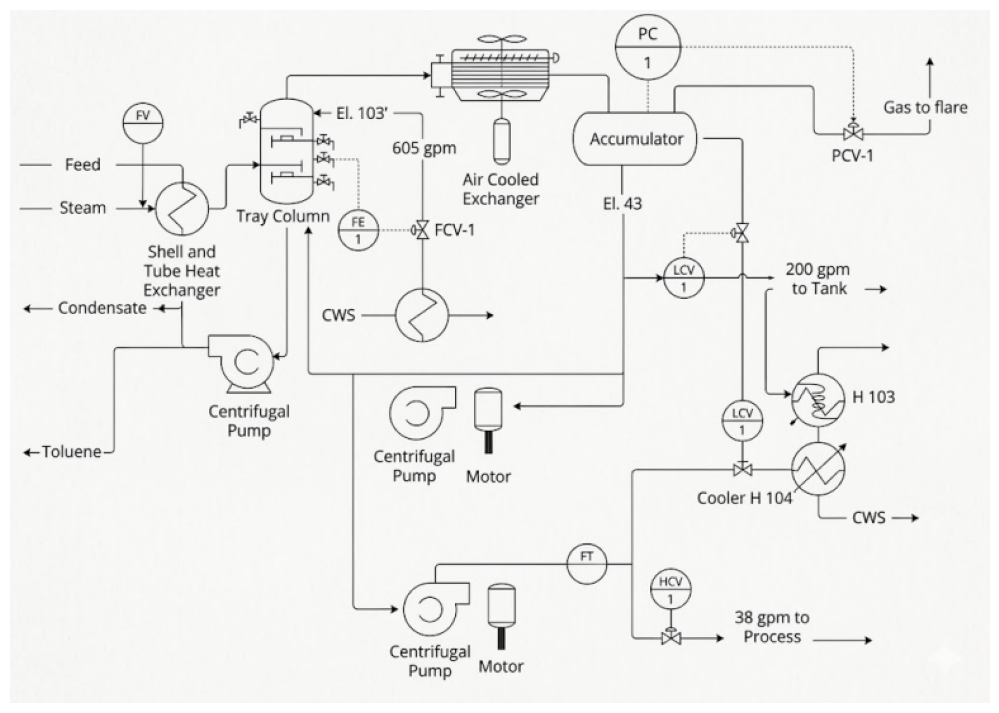

In [2]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

IMAGE_PATH = next(iter(uploaded.keys()))

img = cv2.imread(IMAGE_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image size:", img.shape)

plt.figure(figsize=(14, 9))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

기기 인식 클래스 정의

In [3]:
CLASSES = [
    "pump",
    "motor",
    "column",
    "vessel",
    "heat_exchanger",
    "cooler",
    "control_valve",
    "manual_valve",
    "instrument",
    "other"
]

NUM_CLASSES = len(CLASSES)

YOLO 학습 데이터 준비

    pid_dataset
     images/
        train/
        val/
     labels/
        train/
        val/
    data.yaml

In [6]:
import os
import yaml

# 디렉터리가 없으면 자동으로 생성해 주는 코드 추가
os.makedirs("/content/pid_dataset", exist_ok=True)

data_config = {
    "path": "/content/pid_dataset",
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(CLASSES)}
}

with open("/content/pid_dataset/data.yaml", "w") as f:
    yaml.dump(data_config, f)

print("data.yaml 파일이 성공적으로 생성되었습니다.")

data.yaml 파일이 성공적으로 생성되었습니다.


학습자료 Load

라벨은 YOLO 형식입니다.
class_id x_center y_center width height
좌표는 이미지 크기로 나눈 0~1 사이의 정규화 좌표입니다.
예를 들어 펌프의 위치를 사람이 지정하면 다음과 같이 기록합니다.
0 0.435 0.520 0.075 0.110


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data="/content/pid_dataset/data.yaml",
    epochs=100,
    imgsz=1024,
    batch=4,
    patience=20,
    device=0,
    project="/content/pid_training",
    name="pid_model"
)

학습이 끝나면 다음 파일이 생성됩니다.

/content/pid_training/pid_model/weights/best.pt

Colab에서 GPU 메모리가 부족하면 imgsz=768, batch=2로 낮추면 됩니다.

학습 데이터 준비와 학습 API는 Ultralytics 공식 가이드를 따릅니다.

기기 검출

In [ ]:
model = YOLO(
    "/content/pid_training/pid_model/weights/best.pt"
)

results = model.predict(
    source=IMAGE_PATH,
    imgsz=1024,
    conf=0.35
)

detections = []

for result in results:

    for box in result.boxes:

        cls_id = int(box.cls[0])
        confidence = float(box.conf[0])

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        detections.append({
            "class": CLASSES[cls_id],
            "confidence": confidence,
            "bbox": [x1, y1, x2, y2]
        })

print("Detected:", len(detections))
print(detections)

OCR로 Tag 추출
OCR 결과는 FCV-1, PCV-1, P-101 등의 Tag 후보를 추출합니다.

다음으로 OCR 좌표와 YOLO 기기 좌표를 비교해 가까운 기기에 Tag를 연결해야 합니다. 단, Tag가 기호 내부에 있지 않고 옆에 배치되는 경우가 많으므로 단순히 가장 가까운 기기에 붙이는 것은 확정 판정이 아닙니다.

In [ ]:
import easyocr
import re

reader = easyocr.Reader(["en"], gpu=True)

ocr_results = reader.readtext(
    IMAGE_PATH,
    detail=1
)

tag_pattern = re.compile(
    r'\b(?:P|PC|PT|FT|FE|FV|FCV|LCV|HCV|'
    r'XV|V|E|T|F)[- ]?\d+\b',
    re.IGNORECASE
)

tags = []

for bbox, text, confidence in ocr_results:

    text = text.strip()

    if tag_pattern.search(text):

        xs = [p[0] for p in bbox]
        ys = [p[1] for p in bbox]

        tags.append({
            "text": text,
            "center": [
                sum(xs) / len(xs),
                sum(ys) / len(ys)
            ],
            "confidence": float(confidence)
        })

print(tags)

기기 심벌과 OCR Tag 연결
실제로는 개선이 필요합니다
P&ID에서는 Tag가 기호의 위, 아래, 좌우에 배치되므로 중심점 간 거리만으로 판단하면 잘못 연결될 수 있습니다.

따라서 다음 단계에서는 다음 정보를 함께 사용해야 합니다.
- Tag와 기호 사이의 거리
- Tag의 배치 방향
- 기기 종류와 Tag 접두어의 일치 여부 (예: P-101은 Pump)
- 주변 배관 및 계기 연결 구조
- 다른 기기와의 상대적 거리
그리고 한 Tag가 여러 기기에 중복 연결되지 않도록 해야 합니다.

제안: 이 도면을 기준으로 Tag와 기기 사이의 위치 관계를 분석하는 알고리즘을 추가하겠습니다. 그러면 YOLO가 검출한 기기와 OCR이 읽은 Tag를 Neo4j에 함께 저장할 수 있습니다.

In [ ]:
import numpy as np

def get_box_center(bbox):
    x1, y1, x2, y2 = bbox
    return np.array([(x1+x2)/2, (y1+y2)/2])


def match_tags_to_equipment(
    detections,
    tags,
    max_distance=100
):

    matched = []
    unmatched_tags = []

    for tag in tags:

        tag_center = np.array(tag["center"])

        candidates = []

        for i, det in enumerate(detections):

            box_center = get_box_center(det["bbox"])

            distance = np.linalg.norm(
                tag_center - box_center
            )

            if distance < max_distance:
                candidates.append((i, distance))

        candidates.sort(key=lambda x: x[1])

        if candidates:

            idx, distance = candidates[0]

            matched.append({
                "equipment_index": idx,
                "equipment_class": detections[idx]["class"],
                "tag": tag["text"],
                "distance": float(distance),
                "status": "candidate"
            })

        else:

            unmatched_tags.append(tag)

    return matched, unmatched_tags


matched, unmatched = match_tags_to_equipment(
    detections,
    tags
)

print("Matched candidates:")
for item in matched:
    print(item)

print("Unmatched tags:")
for item in unmatched:
    print(item)

배관 선분 검출
우선 OpenCV의 Hough Line Transform으로 직선 후보를 찾겠습니다.이 단계에서는 배관 이외에도 기기 내부의 선, 문자 밑줄, 기호 일부가 검출될 수 있습니다. 따라서 모든 검출 선을 배관이라고 판단하면 안 됩니다.

In [ ]:
def point_to_box_distance(point, bbox):

    x, y = point
    x1, y1, x2, y2 = bbox

    dx = max(x1 - x, 0, x - x2)
    dy = max(y1 - y, 0, y - y2)

    return np.hypot(dx, dy)


connection_candidates = []

for line in line_segments:

    p1 = line["start"]
    p2 = line["end"]

    near1 = []
    near2 = []

    for i, det in enumerate(detections):

        d1 = point_to_box_distance(p1, det["bbox"])
        d2 = point_to_box_distance(p2, det["bbox"])

        if d1 < 15:
            near1.append((i, d1))

        if d2 < 15:
            near2.append((i, d2))

    for i, d1 in near1:

        for j, d2 in near2:

            if i != j:

                connection_candidates.append({
                    "source_index": i,
                    "target_index": j,
                    "line": line,
                    "distance": float(d1 + d2),
                    "status": "candidate"
                })

print("Connection candidates:",
      len(connection_candidates))


기기와 배관 연결 후보 찾기
배관 선분의 양 끝점이 기기 영역에 가까운지 검사하는 간단한 방법입니다.

중요: 이것은 연결관계의 최종 판정 알고리즘이 아닙니다. 배관이 기기 내부까지 이어지는 경우, 여러 선분으로 끊어진 경우, T자 접속, 단순 교차, 신호선 등이 아직 해결되지 않았습니다. 이 코드는 후보를 만들기 위한 첫 단계입니다.

실제 P&ID에서는 선분을 하나씩 추적하여 연속된 배관 경로를 구성하고, 접속점과 단순 교차점을 구분하는 알고리즘을 추가해야 합니다.

In [ ]:
def point_to_box_distance(point, bbox):

    x, y = point
    x1, y1, x2, y2 = bbox

    dx = max(x1 - x, 0, x - x2)
    dy = max(y1 - y, 0, y - y2)

    return np.hypot(dx, dy)


connection_candidates = []

for line in line_segments:

    p1 = line["start"]
    p2 = line["end"]

    near1 = []
    near2 = []

    for i, det in enumerate(detections):

        d1 = point_to_box_distance(p1, det["bbox"])
        d2 = point_to_box_distance(p2, det["bbox"])

        if d1 < 15:
            near1.append((i, d1))

        if d2 < 15:
            near2.append((i, d2))

    for i, d1 in near1:

        for j, d2 in near2:

            if i != j:

                connection_candidates.append({
                    "source_index": i,
                    "target_index": j,
                    "line": line,
                    "distance": float(d1 + d2),
                    "status": "candidate"
                })

print("Connection candidates:",
      len(connection_candidates))

Neo4j 연결 및 저장
이제 데이터베이스 부분입니다.

Neo4j AuraDB를 사용하거나 외부에서 접속 가능한 Neo4j 서버를 준비하면 됩니다. Colab에서 localhost로 접속할 수는 없으므로 Neo4j의 접속 주소가 필요합니다.

Neo4j Python Driver는 공식 라이브러리 neo4j를 사용합니다.

In [ ]:
from neo4j import GraphDatabase
from getpass import getpass

NEO4J_URI = input("Neo4j URI: ")
NEO4J_USER = input("Neo4j Username: ")
NEO4J_PASSWORD = getpass("Neo4j Password: ")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USER, NEO4J_PASSWORD)
)

driver.verify_connectivity()

print("Neo4j connected")

DB 구조 생성
Dawing 도면 정보


 Equipment
  Pump, Vessel 등

   Equipment 연결된 기기
   Instrument 계기 및 밸브

이 코드에서는 아직 Tag가 연결되지 않았으므로 tag=None으로 저장합니다. OCR과 기기 사이의 매칭이 끝나면 Tag를 업데이트하면 됩니다.   

In [ ]:
DRAWING_ID = "PID_TEST_001"

def save_drawing(tx):

    tx.run("""
        MERGE (d:Drawing {id: $id})
        SET d.filename = $filename,
            d.source_type = "image",
            d.created_at = datetime()
    """,
    id=DRAWING_ID,
    filename=IMAGE_PATH
    )


def save_equipment(tx, equipment):

    tx.run("""
        MATCH (d:Drawing {id: $drawing_id})

        MERGE (e:Equipment {id: $id})

        SET e.class = $class,
            e.tag = $tag,
            e.confidence = $confidence,
            e.bbox = $bbox,
            e.extraction_status = "unverified"

        MERGE (e)-[:FOUND_IN]->(d)
    """, **equipment)


with driver.session() as session:

    session.execute_write(save_drawing)

    for i, det in enumerate(detections):

        equipment = {
            "drawing_id": DRAWING_ID,
            "id": f"{DRAWING_ID}_E{i:04d}",
            "class": det["class"],
            "tag": None,
            "confidence": det["confidence"],
            "bbox": det["bbox"]
        }

        session.execute_write(
            save_equipment,
            equipment
        )

print("Equipment saved to Neo4j")

연결 후보 저장

이렇게 하면 Neo4j에서 확정되지 않은 연결을 구분할 수 있습니다. 검증을 통과한 관계만 나중에 CONNECTED_TO로 승인하면 됩니다.

In [ ]:
def save_connection_candidate(tx, source_id,
                              target_id, distance):

    tx.run("""
        MATCH (a:Equipment {id: $source})
        MATCH (b:Equipment {id: $target})

        MERGE (a)-[r:POSSIBLE_CONNECTION
            {drawing_id: $drawing_id}]->(b)

        SET r.distance = $distance,
            r.status = "unverified"
    """,
    source=source_id,
    target=target_id,
    drawing_id=DRAWING_ID,
    distance=distance
    )


with driver.session() as session:

    for c in connection_candidates:

        source_id = (
            f"{DRAWING_ID}_E{c['source_index']:04d}"
        )

        target_id = (
            f"{DRAWING_ID}_E{c['target_index']:04d}"
        )

        session.execute_write(
            save_connection_candidate,
            source_id,
            target_id,
            c["distance"]
        )

print("Connection candidates saved")

Neo4j에서 확인하기
Neo4j Browser에서 다음 Cypher를 실행합니다.

MATCH (e:Equipment)-[:FOUND_IN]->(d:Drawing)
RETURN e, d

MATCH (a:Equipment)-[r:POSSIBLE_CONNECTION]->(b:Equipment)
RETURN a, r, b

MATCH (e:Equipment)
RETURN e.class, count(e) AS count
ORDER BY count DESC

제가 보기에는 신경망 자체보다 학습 데이터 구성과 연결관계 추출이 중요합니다.

현재 도면을 대상으로 다음 세 가지를 먼저 확인하는 것이 좋겠습니다.
1. YOLO가 펌프, 열교환기, 밸브, 계기를 구분할 수 있는가?
2. OCR이 FCV-1, PCV-1, LCV-1 등을 정확히 읽을 수 있는가?
3. 배관이 여러 번 꺾이거나 분기되어도 동일한 연결 경로로 추적할 수 있는가?
특히 세 번째가 중요합니다. 기기 검출은 객체 인식 문제지만, 배관 연결은 도면의 위상 구조(topology)를 복원하는 문제이기 때문입니다.

제가 제안하는 다음 개발 순서는 이렇습니다.
- 먼저 지금 그림을 포함한 P&ID 이미지 10~20장을 모읍니다.
- 기기별 사각형 라벨을 작성합니다.
- YOLO를 학습시킵니다.
- 검출된 기기와 OCR Tag를 연결합니다.
- 배관 연결 알고리즘을 개선합니다.
- 마지막으로 Neo4j에 저장하고 원본 그림 위에 결과를 표시합니다.
처음부터 모든 P&ID 기호를 인식하려고 하지 말고, 우선 펌프·탱크·열교환기·밸브·계기 다섯 종류를 안정적으로 인식하도록 만드는 것이 좋겠습니다.